# KNN Assignment

### Assignment 1: General Questions

## 1. Feature Scaling Methods

Feature scaling brings numerical features to a comparable scale.

**1. StandardScaler**

Transforms data to mean 0 and standard deviation 1.

Formula: \(z = \frac{x-\mu}{\sigma}\)

**Use:** SVM, Logistic Regression, KNN, PCA.

**Limitation:** Sensitive to outliers.

**2. MinMaxScaler**

Scales values, usually between 0 and 1.

Formula: \(x' = \frac{x-x_{\min}}{x_{\max}-x_{\min}}\)

**Use:** Neural networks and KNN.

**Limitation:** Sensitive to outliers.

**3. RobustScaler**

Uses the median and interquartile range (IQR).

Formula: \(x' = \frac{x-\text{Median}}{Q_3-Q_1}\)

**Use:** Datasets containing outliers, such as income and financial data.

**4. MaxAbsScaler**

Divides values by the maximum absolute value.

**Use:** Sparse datasets; preserves zero values.

**5. Normalizer**

Scales each sample to unit norm.

**Use:** Text classification, TF-IDF vectors, and cosine similarity.

**6. PowerTransformer**

Transforms feature distributions to reduce skewness.

**Use:** Highly skewed numerical data.

**7. QuantileTransformer**

Maps data according to its distribution.

**Use:** Highly non-normal data with extreme values.

| Method | Suitable scenario |
|---|---|
| StandardScaler | SVM, Logistic Regression, PCA |
| MinMaxScaler | Neural networks, KNN |
| RobustScaler | Data with outliers |
| MaxAbsScaler | Sparse data |
| Normalizer | Text classification |
| PowerTransformer | Skewed data |
| QuantileTransformer | Non-normal distributions |

**Conclusion:** Select the scaling method according to the dataset and algorithm. Tree-based models such as Random Forest generally do not require scaling.

---

## 2. Classification Model: Breast Cancer Dataset

The Breast Cancer Wisconsin dataset predicts whether a tumour is malignant or benign using numerical measurements. The example uses scikit-learn's built-in dataset; a Kaggle CSV can be substituted if required.

**Step 1: Load the dataset**

```python
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

df["diagnosis"] = df["target"].map({
    0: "malignant",
    1: "benign"
})
df.drop(columns=["target"], inplace=True)

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
```

**Step 2: Exploratory Data Analysis**

```python
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df["diagnosis"].value_counts())

sns.countplot(data=df, x="diagnosis")
plt.show()

sns.heatmap(
    df.drop(columns="diagnosis").corr(),
    cmap="coolwarm"
)
plt.show()
```

**Step 3: Separate features and target**

```python
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]
```

**Step 4: Split the dataset**

```python
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)
```

**Step 5: Handle missing values and scale features**

```python
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
```

The dataset contains numerical features, so categorical encoding is unnecessary. The imputer handles missing numerical values if present.

**Step 6: Build the model**

```python
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=5000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
```

**Step 7: Evaluate the model**

```python
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, pos_label="malignant"
))
print("Recall:", recall_score(
    y_test, y_pred, pos_label="malignant"
))
print("F1-score:", f1_score(
    y_test, y_pred, pos_label="malignant"
))
print(classification_report(y_test, y_pred))
```

**Step 8: Confusion matrix**

```python
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test, y_pred,
    labels=["malignant", "benign"]
)

ConfusionMatrixDisplay(
    cm, display_labels=["Malignant", "Benign"]
).plot(cmap="Blues")

plt.show()
```

**Step 9: Hyperparameter tuning**

```python
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"]
}

grid = GridSearchCV(
    model, param_grid,
    cv=5, scoring="f1_macro", n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)

best_model = grid.best_estimator_
tuned_pred = best_model.predict(X_test)

print("Tuned accuracy:",
      accuracy_score(y_test, tuned_pred))
print(classification_report(y_test, tuned_pred))
```

**Conclusion:** The workflow covers loading, EDA, preprocessing, feature scaling, model training, evaluation, and hyperparameter tuning. Compare the baseline and tuned models using the same test set.

---

## 3. Random Forest with `random_state=0` and `random_state=42`

Random Forest combines multiple decision trees. Randomness is introduced through bootstrap sampling and feature selection.

**Step 1: Prepare the data**

Use the training and testing sets from Question 2.

```python
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
```

**Step 2: Train each model five times**

```python
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

results = []

for seed in [0, 42]:
    for run in range(1, 6):
        model = RandomForestClassifier(
            n_estimators=100,
            random_state=seed
        )

        model.fit(X_train_processed, y_train)
        pred = model.predict(X_test_processed)

        results.append({
            "Random State": seed,
            "Run": run,
            "Accuracy": accuracy_score(y_test, pred),
            "F1 Score": f1_score(
                y_test, pred, pos_label="malignant"
            )
        })

results_df = pd.DataFrame(results)
print(results_df)
```

**Step 3: Compare results**

```python
print(
    results_df.groupby("Random State")[
        ["Accuracy", "F1 Score"]
    ].agg(["mean", "std"])
)
```

**Observations:**

- All five runs with the same fixed seed should produce identical results under the same conditions.
- Results may differ between seeds 0 and 42 because the trees are constructed using different random choices.
- Neither seed is inherently better.
- Standard deviation across repeated runs with the same seed will generally be zero.

**Conclusion:** A fixed random state ensures reproducibility. To measure variability due to randomness, compare multiple different seeds or use repeated cross-validation.

---

## 4. Three-Class Confusion Matrix

A confusion matrix compares actual labels with predicted labels. Consider three classes: A, B, and C.

| Actual / Predicted | Class A | Class B | Class C |
|---|---:|---:|---:|
| **Class A** | 40 | 5 | 3 |
| **Class B** | 4 | 35 | 6 |
| **Class C** | 2 | 7 | 38 |

The diagonal cells represent correct predictions; off-diagonal cells represent incorrect predictions.

- 40: Class A correctly predicted as A.
- 5: Class A incorrectly predicted as B.
- 3: Class A incorrectly predicted as C.
- 4: Class B incorrectly predicted as A.
- 35: Class B correctly predicted as B.
- 6: Class B incorrectly predicted as C.
- 2: Class C incorrectly predicted as A.
- 7: Class C incorrectly predicted as B.
- 38: Class C correctly predicted as C.

**Definitions:**

- **True Positive (TP):** An observation correctly predicted as the class being evaluated.
- **False Positive (FP):** An observation from another class incorrectly predicted as the evaluated class.
- **False Negative (FN):** An observation belonging to the evaluated class incorrectly predicted as another class.
- **True Negative (TN):** An observation from another class correctly not predicted as the evaluated class.

In multiclass classification, these values are calculated for each class using a one-vs-rest approach.

| Class | TP | FP | FN | TN |
|---|---:|---:|---:|---:|
| A | 40 | 6 | 8 | 86 |
| B | 35 | 12 | 10 | 83 |
| C | 38 | 9 | 9 | 84 |

**Formulas:**

**1. Precision**

`Precision = TP / (TP + FP)`

Precision measures how many predicted positive cases are actually positive.

**2. Recall**

`Recall = TP / (TP + FN)`

Recall measures how many actual positive cases are correctly identified.

**3. F1-score**

`F1-score = 2 * (Precision * Recall) / (Precision + Recall)`

F1-score is the harmonic mean of precision and recall.

**4. Accuracy**

`Accuracy = Sum of diagonal cells / Total observations`

For the given matrix:

`Accuracy = (40 + 35 + 38) / 170`

`Accuracy = 113 / 170 = 66.47%`

**Conclusion:** A confusion matrix identifies correct predictions and class-specific errors. Precision, recall, and F1-score can be calculated separately for each class.

## Complete KNN Analysis using `train.csv`

Each task is kept in its own cell below.


In [1]:
lazy import numpy as np
lazy import pandas as pd
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns

# 1. Load the dataset and describe its structure
df = pd.read_csv('train.csv')
print('Dataset shape:', df.shape)
print('Number of rows:', df.shape[0])
print('Number of columns:', df.shape[1])
print('First 5 rows:')
print(df.head())
print(df.info())


Dataset shape: (42000, 785)
Number of rows: 42000
Number of columns: 785
First 5 rows:
   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0  

Label counts:
 label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64


C:\Users\Ashu\AppData\Local\Temp\ipykernel_6408\3916640502.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


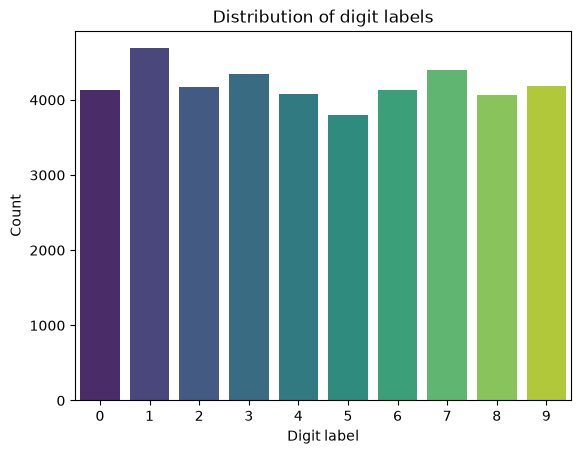

Average pixel intensity: 33.408911169825075
Minimum pixel value: 0
Maximum pixel value: 255


In [2]:
# 2. Exploratory data analysis on labels and pixel values
label_counts = df['label'].value_counts().sort_index()
print('Label counts:\n', label_counts)
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Distribution of digit labels')
plt.xlabel('Digit label')
plt.ylabel('Count')
plt.show()

pixel_cols = [c for c in df.columns if c.startswith('pixel')]
pixel_values = df[pixel_cols].values
print('Average pixel intensity:', pixel_values.mean())
print('Minimum pixel value:', pixel_values.min())
print('Maximum pixel value:', pixel_values.max())

# Observations: the labels are fairly balanced across digits 0-9, and most pixels are black (0) with active digit regions around the center.


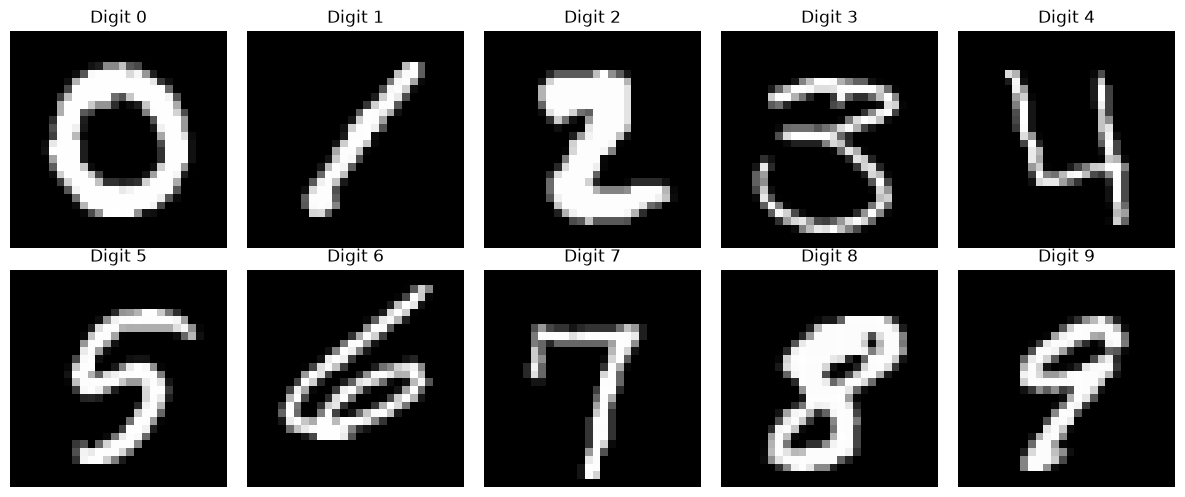

In [3]:
# 3. Visualize a few sample digit images
sample_digits = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()
for idx, digit in enumerate(sample_digits):
    img = df[df['label'] == digit].iloc[0, 1:].values.reshape(28, 28)
    axes[idx].imshow(img, cmap='gray')
    axes[idx].set_title(f'Digit {digit}')
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

# These images show that digits have distinct shapes, though some digits (such as 3 and 8, or 4 and 9) are visually similar.


In [4]:
# 4. Normalize the pixel values
X = df.drop(columns=['label']).values.astype(np.float32) / 255.0
y = df['label'].values
print('Normalized pixel range:', X.min(), 'to', X.max())

# KNN uses distance calculations, so normalization is important. If raw pixel values are used, the larger brightness values can dominate the distance metric.


Normalized pixel range: 0.0 to 1.0


In [5]:
# 5. Split into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Training samples: {X_train.shape[0]}')
print(f'Testing samples: {X_test.shape[0]}')

# An 80:20 split is a standard choice because it preserves enough training data while keeping a fair test set for evaluation.


Training samples: 33600
Testing samples: 8400


In [6]:
# 6. Train KNN and experiment with different values of k
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

k_values = list(range(1, 21, 2))
results = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results.append((k, acc))
    print(f'k={k:2d} -> Accuracy: {acc:.4f}')


k= 1 -> Accuracy: 0.9652
k= 3 -> Accuracy: 0.9667
k= 5 -> Accuracy: 0.9663
k= 7 -> Accuracy: 0.9642
k= 9 -> Accuracy: 0.9631
k=11 -> Accuracy: 0.9618
k=13 -> Accuracy: 0.9601
k=15 -> Accuracy: 0.9586
k=17 -> Accuracy: 0.9565
k=19 -> Accuracy: 0.9539


In [7]:
# 7. Evaluate the best model using performance metrics
from sklearn.metrics import classification_report

best_k, best_acc = max(results, key=lambda x: x[1])
best_model = KNeighborsClassifier(n_neighbors=best_k)
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)
print(f'Best k: {best_k} with accuracy {best_acc:.4f}')
print(classification_report(y_test, y_pred_best))

# The model's accuracy and F1-scores indicate how reliable it is across all classes, not just the majority class.


Best k: 3 with accuracy 0.9667
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       827
           1       0.95      1.00      0.97       937
           2       0.98      0.96      0.97       835
           3       0.96      0.96      0.96       870
           4       0.97      0.96      0.97       814
           5       0.95      0.96      0.96       759
           6       0.98      0.99      0.99       827
           7       0.97      0.97      0.97       880
           8       0.99      0.90      0.94       813
           9       0.95      0.96      0.95       838

    accuracy                           0.97      8400
   macro avg       0.97      0.97      0.97      8400
weighted avg       0.97      0.97      0.97      8400



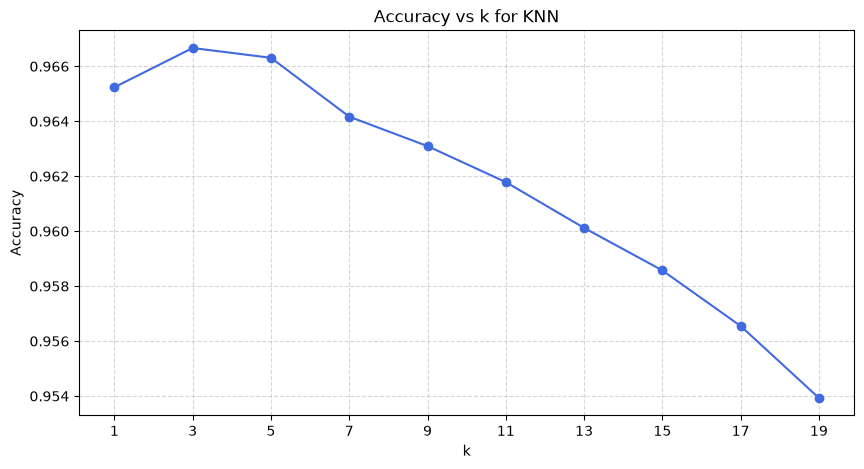

Optimal k value: 3


In [8]:
# 8. Plot accuracy versus k and identify the optimal value
k_list, acc_list = zip(*results)
plt.figure(figsize=(10, 5))
plt.plot(k_list, acc_list, marker='o', color='royalblue')
plt.title('Accuracy vs k for KNN')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f'Optimal k value: {best_k}')
# As k increases, the model becomes smoother, but if k is too large it may oversimplify the decision boundary and reduce accuracy.


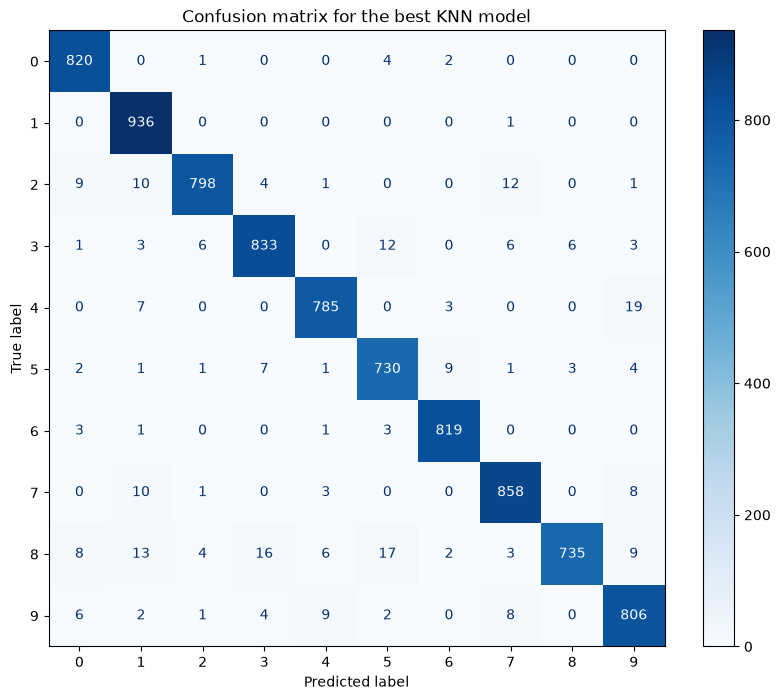

Top misclassifications:
True 4 predicted as 9: 19 times
True 8 predicted as 5: 17 times
True 8 predicted as 3: 16 times
True 8 predicted as 1: 13 times
True 2 predicted as 7: 12 times
True 3 predicted as 5: 12 times
True 2 predicted as 1: 10 times
True 7 predicted as 1: 10 times
True 2 predicted as 0: 9 times
True 5 predicted as 6: 9 times


In [9]:
# 9. Generate and interpret the confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_best, labels=range(10))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues')
ax.set_title('Confusion matrix for the best KNN model')
plt.show()

misclassifications = []
for true_digit in range(10):
    for pred_digit in range(10):
        if true_digit != pred_digit and cm[true_digit, pred_digit] > 0:
            misclassifications.append((true_digit, pred_digit, cm[true_digit, pred_digit]))
print('Top misclassifications:')
for true_digit, pred_digit, count in sorted(misclassifications, key=lambda x: x[2], reverse=True)[:10]:
    print(f'True {true_digit} predicted as {pred_digit}: {count} times')

# Similar digits such as 3 and 8 or 4 and 9 are often confused because their shapes overlap.


In [10]:
# 10. Apply PCA and compare with the original model
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
knn_pca = KNeighborsClassifier(n_neighbors=best_k)
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)
print(f'Accuracy without PCA: {best_acc:.4f}')
print(f'Accuracy with PCA (50 components): {acc_pca:.4f}')

# PCA usually reduces dimensionality and speeds up computation, but the effect on accuracy depends on how much information is retained.


Accuracy without PCA: 0.9667
Accuracy with PCA (50 components): 0.9720


In [11]:
# 11. Compare different KNN distance metrics
for metric in ['euclidean', 'manhattan']:
    model_metric = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    model_metric.fit(X_train, y_train)
    y_pred_metric = model_metric.predict(X_test)
    acc_metric = accuracy_score(y_test, y_pred_metric)
    print(f'Metric = {metric}: Accuracy = {acc_metric:.4f}')

# Euclidean distance is the default and often works well, while Manhattan distance can perform differently depending on the data geometry and sparsity.


Metric = euclidean: Accuracy = 0.9667
Metric = manhattan: Accuracy = 0.9604
